<a href="https://colab.research.google.com/github/sanyasana1/MN/blob/main/%D0%9B%D0%A0_7_%D0%9B%D0%B0%D0%B7%D0%B0%D1%80%D0%B5%D0%BD%D0%BA%D0%BE_3_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 7
## Логістична регресія. «Врятувати принцесу»


**Мета:** виконати бінарну класифікацію для датасету *Cure the Princess*, побудувати логістичну регресію, підібрати її параметри та порівняти з SVM і деревом рішень.

**Датасет:** [завантажити файл](https://drive.google.com/file/d/1ctefpJ5A0ZiwewxqLaC3RBeydLKLTgvH/view?usp=drive_link).

**Завдання:** допишіть код у клітинках із позначкою `TODO`, запустіть усі потрібні клітинки, після кожного етапу коротко прокоментуйте результати. Готові числові результати у шаблоні навмисно не наведено.

https://www.kaggle.com/datasets/unmoved/cure-the-princess

### 1. Імпорт бібліотек

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, f1_score

### 2. Завантаження даних

Використайте **один** із двох способів. Якщо обираєте завантаження з комп'ютера, виконайте перший блок. Якщо KaggleHub — другий. Файл має назву `data.csv`.

In [2]:
# Варіант 1. Завантаження файлу в Google Colab
from google.colab import files
files.upload()
df = pd.read_csv('data.csv')
df.head()

FileNotFoundError: [Errno 2] No such file or directory: 'data.csv'

In [3]:
# Варіант 2. Завантаження датасету через KaggleHub
import kagglehub
import os
path = kagglehub.dataset_download('unmoved/cure-the-princess')
df = pd.read_csv(os.path.join(path, 'data.csv'))
df.head()

Using Colab cache for faster access to the 'cure-the-princess' dataset.


,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
0,2.4,18.7,18.4,27.9,7.9,9.6,18.3,13.2,2.5,26.0,10.5,26.2,12.5,0
1,2.1,6.0,15.0,13.3,15.6,13.1,11.0,5.0,7.2,26.0,1.5,13.3,6.2,0
2,17.2,13.9,23.8,6.8,10.7,15.8,19.4,2.7,15.4,21.2,11.1,16.6,11.4,1
3,8.4,9.7,6.8,26.9,4.6,29.1,14.6,19.7,18.0,20.8,13.6,13.9,8.1,1
4,22.1,10.8,16.4,10.5,22.0,23.4,2.6,18.2,23.8,11.3,5.5,16.8,16.2,0


### Опис даних

Цільова змінна **`Cured`**: `1` — принцесу вилікувано; `0` — не вилікувано. Інші стовпці — характеристики магічних інгредієнтів.

1. **Phoenix Feather** (Перо фенікса) — перо міфічної птиці фенікса, який згорає, а потім відроджується з власного попелу. Це символізує відродження, вічне життя та силу.

2. **Unicorn Horn** (Ріг єдинорога) — ріг міфічної істоти єдинорога, який часто асоціюється з чистотою та цілющою силою. У багатьох легендах вважалося, що ріг єдинорога має магічні властивості, зокрема здатність лікувати отруєння.

3. **Dragon's Blood** (Кров дракона) — кров дракона, міфічної істоти, часто вважається дуже потужним магічним зіллям або елементом. Це може символізувати силу, енергію чи небезпеку.

4. **Mermaid Tears**(Сльози русалки) — сльози міфічної істоти — русалки. У різних культурах їх вважають рідкісним і дуже цінним елементом, що має магічні властивості, часто пов'язані з любов'ю або трагічними подіями.

5. **Fairy Dust** (Пилок феї) — магічний пилок, що належить феям у народних казках. Зазвичай він використовується для чарівних перетворень, польотів або інших магічних дій.

6. **Goblin Toes** (Палець гобліна) — палець гобліна, вигаданої істоти з міфів, що зазвичай асоціюється з хитрістю і злісними чарами. Цей елемент може мати магічну силу або використовуватися в темних чарах.

7. **Witch's Brew** (Зілля відьми) — зілля, яке варить відьма, часто містить магічні або отруйні інгредієнти. Це часто асоціюється з темною магією або чарами.

8. **Griffin Claw** (Лапа грифона) — лапа грифона, міфічної істоти, що є поєднанням орла і лева. Грифон символізує силу та відвагу, а його лапа може вважатися потужним магічним предметом.

9. **Troll Hair** (Волосся троля) — волосся троля, ще однієї міфічної істоти, часто описуваної як агресивна та неприємна істота. Волосся троля може бути використане в магічних або темних ритуалах.

10. **Kraken Ink** (Чорнила кракена) — чорнила, що отримуються від кракена, гігантської морської істоти. У фентезі вони можуть використовуватись для темних магічних ритуалів або для створення важливих символів.

11. **Minotaur Horn** (Ріг минотавра) — ріг минотавра, міфічного чудовиська з головою бика і тілом людини. Ріг минотавра може символізувати силу і агресію, і в магічному контексті бути потужним інгредієнтом.

12. **Basilisk Scale** (Луска базиліска) — луска базиліска, міфічної істоти, яка може вбивати своїм поглядом. Луска базиліска у фентезі часто використовується як компонент у потужних зіллях або зброї.

13. **Chimera Fang** (Зуб хімери) — зуб хімери, міфічної істоти, яка поєднує різні тварини, такі як лев, коза і змія. Зуб хімери часто використовується в магічних зіллях або як символ сили та багатофункціональності.

14. **Cured** (Вилікувана) — цільова змінна: 1 — принцесу вилікувано, 0 — не вилікувано.

### 3. Первинний огляд датасету

Дослідіть структуру та розміри даних, пропущені значення, дублікати й описову статистику. Дайте короткий висновок про якість даних.

In [4]:
display(df.head())
print("\nІнформація про стовпці та типи даних:")
df.info()
print(f"\nРозмір датасету: {df.shape[0]} рядків × {df.shape[1]} стовпців")
print("\nНазви стовпців:")
print(df.columns.tolist())

,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
0,2.4,18.7,18.4,27.9,7.9,9.6,18.3,13.2,2.5,26.0,10.5,26.2,12.5,0
1,2.1,6.0,15.0,13.3,15.6,13.1,11.0,5.0,7.2,26.0,1.5,13.3,6.2,0
2,17.2,13.9,23.8,6.8,10.7,15.8,19.4,2.7,15.4,21.2,11.1,16.6,11.4,1
3,8.4,9.7,6.8,26.9,4.6,29.1,14.6,19.7,18.0,20.8,13.6,13.9,8.1,1
4,22.1,10.8,16.4,10.5,22.0,23.4,2.6,18.2,23.8,11.3,5.5,16.8,16.2,0



Інформація про стовпці та типи даних:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2338 entries, 0 to 2337
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Phoenix Feather  2338 non-null   float64
 1   Unicorn Horn     2338 non-null   float64
 2   Dragon's Blood   2338 non-null   float64
 3   Mermaid Tears    2338 non-null   float64
 4   Fairy Dust       2338 non-null   float64
 5   Goblin Toes      2338 non-null   float64
 6   Witch's Brew     2338 non-null   float64
 7   Griffin Claw     2338 non-null   float64
 8   Troll Hair       2338 non-null   float64
 9   Kraken Ink       2338 non-null   float64
 10  Minotaur Horn    2338 non-null   float64
 11  Basilisk Scale   2338 non-null   float64
 12  Chimera Fang     2338 non-null   float64
 13  Cured            2338 non-null   int64  
dtypes: float64(13), int64(1)
memory usage: 255.8 KB

Розмір датасету: 2338 рядків × 14 стовпців

Назви стовпців:
['Ph

In [5]:
print("Пропущені значення:")
display(df.isnull().sum().to_frame(name='Кількість пропусків'))
print("Кількість повністю дубльованих рядків:", df.duplicated().sum())

Пропущені значення:


,Кількість пропусків
Phoenix Feather,0
Unicorn Horn,0
Dragon's Blood,0
Mermaid Tears,0
Fairy Dust,0
Goblin Toes,0
Witch's Brew,0
Griffin Claw,0
Troll Hair,0
Kraken Ink,0


Кількість повністю дубльованих рядків: 0


In [6]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
Phoenix Feather,2338.0,15.365697,8.669969,1.0,8.500,14.7,21.300,42.1
Unicorn Horn,2338.0,10.946749,7.225162,1.0,5.300,9.5,15.575,34.1
Dragon's Blood,2338.0,16.115654,8.372518,1.0,9.600,15.8,22.000,40.8
Mermaid Tears,2338.0,13.627973,7.545244,1.0,7.600,13.1,19.000,35.8
Fairy Dust,2338.0,15.069504,8.349340,1.0,8.625,14.5,20.700,40.4
Goblin Toes,2338.0,14.157271,7.831476,1.0,7.900,13.5,19.500,37.8
Witch's Brew,2338.0,12.328914,7.709753,1.0,6.325,11.2,16.900,37.3
Griffin Claw,2338.0,14.911206,8.132678,1.0,8.400,14.4,20.500,39.4
Troll Hair,2338.0,16.871685,9.579027,1.0,8.900,16.3,24.000,44.8
Kraken Ink,2338.0,14.890590,8.014197,1.0,8.800,14.4,20.400,39.5


**Висновок за первинним оглядом:**  
_Напишіть тут, чи є пропуски, дублікати та які особливості даних помітили._

### 4. Поділ даних на навчальну й тестову вибірки

Відокремте `Cured` від ознак. Поділіть дані у співвідношенні **80% / 20%** із `random_state=42`.

**Важливо:** дослідження кореляцій і викидів, а також обчислення параметрів стандартизації виконуйте **тільки на навчальній вибірці**.

In [7]:
if 'Cured' not in df.columns:
    raise KeyError("У датасеті не знайдено цільовий стовпець 'Cured'. Перевірте назви стовпців.")
if df['Cured'].isna().any():
    raise ValueError("У цільовій змінній Cured є пропуски. Їх потрібно опрацювати перед поділом.")
X = df.drop(columns='Cured')
y = df['Cured'].astype(int)

non_numeric = X.select_dtypes(exclude=np.number).columns.tolist()
if non_numeric:
    raise TypeError(f"Знайдено нечислові ознаки: {non_numeric}. Потрібно закодувати їх перед навчанням.")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("y_train:", y_train.shape, "| y_test:", y_test.shape)

X_train: (1870, 13) | X_test: (468, 13)
y_train: (1870,) | y_test: (468,)


### 5. Баланс класів на навчальній вибірці

In [8]:
class_counts = y_train.value_counts().sort_index()
display(class_counts.rename_axis('Клас Cured').to_frame('Кількість'))
print("Частки класів:")
display((y_train.value_counts(normalize=True).sort_index() * 100).round(2).rename('Частка, %'))

,Кількість
Клас Cured,
0,941
1,929


Частки класів:


,"Частка, %"
Cured,
0,50.32
1,49.68


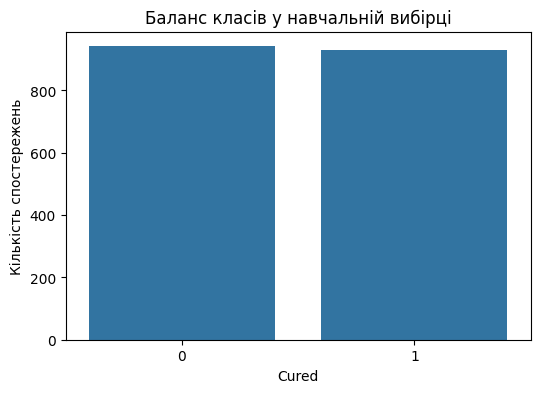

In [9]:
plt.figure(figsize=(6, 4))
sns.countplot(x=y_train)
plt.title('Баланс класів у навчальній вибірці')
plt.xlabel('Cured')
plt.ylabel('Кількість спостережень')
plt.show()

**Висновок:**  
_Чи збалансовані класи? Чому це може вплинути на оцінку моделі?_

### 6. Дослідження викидів на навчальних даних

Побудуйте діаграми розмаху для ознак `X_train`. За правилом **1,5 IQR** знайдіть кількість потенційних викидів у кожній ознаці.

На основному етапі **не видаляйте викиди автоматично**. За бажанням пізніше проведіть окремий експеримент із видаленням тільки з навчальної вибірки.

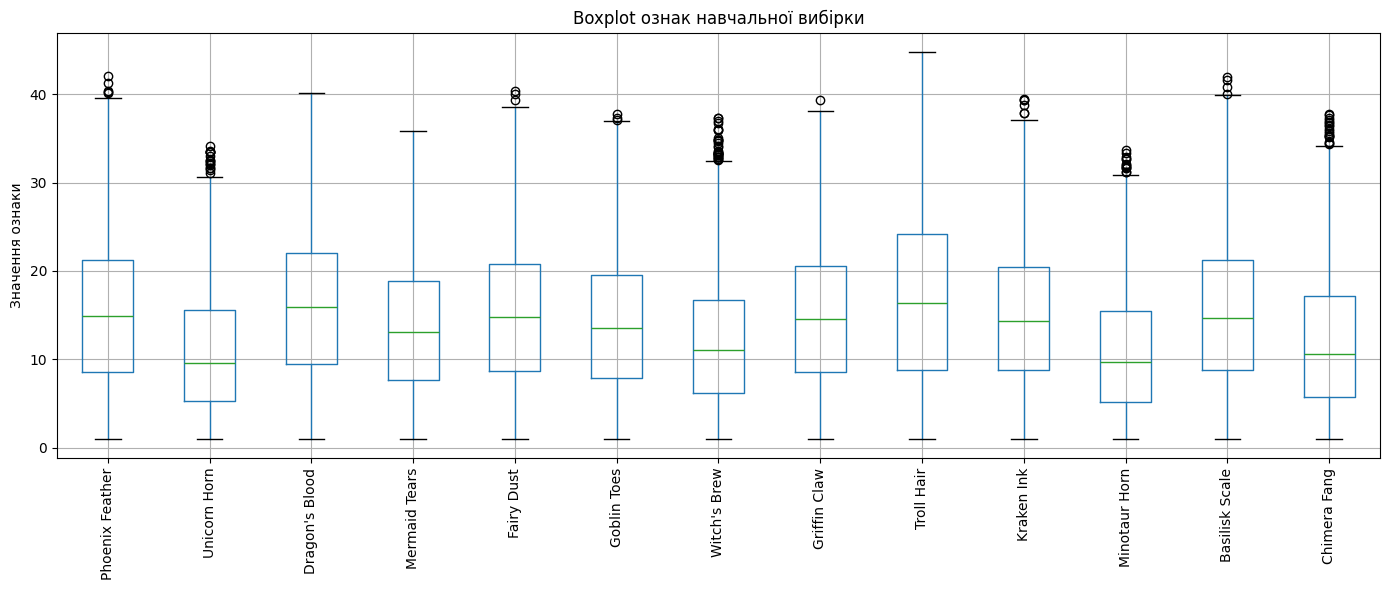

In [10]:
ax = X_train.boxplot(figsize=(14, 6), rot=90)
ax.set_title('Boxplot ознак навчальної вибірки')
ax.set_ylabel('Значення ознаки')
plt.tight_layout()
plt.show()

In [11]:
q1 = X_train.quantile(0.25)
q3 = X_train.quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outlier_counts = ((X_train < lower_bound) | (X_train > upper_bound)).sum()
outlier_counts = outlier_counts.sort_values(ascending=False)
display(outlier_counts.rename('Кількість потенційних викидів').to_frame())
print("Ознака з найбільшою кількістю потенційних викидів:",
      outlier_counts.index[0], "—", int(outlier_counts.iloc[0]))

,Кількість потенційних викидів
Witch's Brew,31
Chimera Fang,18
Unicorn Horn,17
Minotaur Horn,13
Kraken Ink,6
Phoenix Feather,5
Basilisk Scale,4
Fairy Dust,3
Goblin Toes,3
Griffin Claw,1


Ознака з найбільшою кількістю потенційних викидів: Witch's Brew — 31


**Висновок про викиди:**  
_У яких ознаках їх найбільше? Чому не варто без перевірки видаляти всі такі рядки?_

### 7. Кореляційний аналіз на навчальній вибірці

1. Побудуйте кореляційну матрицю ознак **за модулем** (`.abs()`).
2. Відобразіть її у вигляді `heatmap` із **замаскованим верхнім трикутником** (`np.triu`).
3. Окремо знайдіть кореляцію ознак із цільовою змінною `Cured` **тільки для навчальної вибірки**.

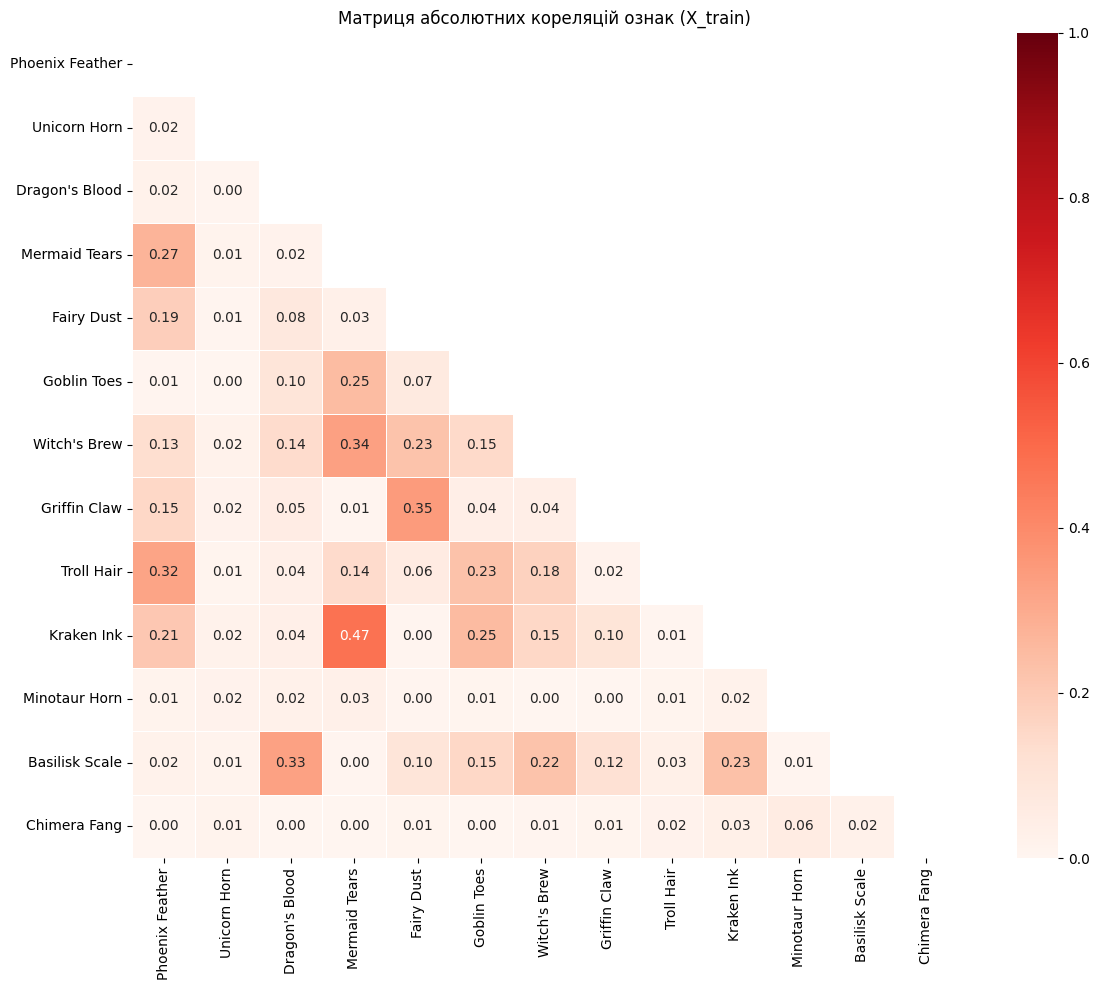

Найбільш корельовані пари ознак:


Абсолютна кореляція
Mermaid Tears   Kraken Ink                 0.473299
Fairy Dust      Griffin Claw               0.348980
Mermaid Tears   Witch's Brew               0.335879
Dragon's Blood  Basilisk Scale             0.330867
Phoenix Feather Troll Hair                 0.322618
                Mermaid Tears              0.270597
Goblin Toes     Kraken Ink                 0.250830
Mermaid Tears   Goblin Toes                0.247854
Kraken Ink      Basilisk Scale             0.232700
Goblin Toes     Troll Hair                 0.229020

In [12]:
mtx = X_train.corr().abs()
mask = np.triu(np.ones_like(mtx, dtype=bool))

plt.figure(figsize=(13, 10))
sns.heatmap(mtx, mask=mask, annot=True, fmt='.2f', cmap='Reds',
            vmin=0, vmax=1, square=True, linewidths=0.5)
plt.title('Матриця абсолютних кореляцій ознак (X_train)')
plt.tight_layout()
plt.show()

upper_corr = mtx.where(np.triu(np.ones(mtx.shape), k=1).astype(bool))
pairs = upper_corr.stack().sort_values(ascending=False)
print("Найбільш корельовані пари ознак:")
display(pairs.head(10).rename('Абсолютна кореляція').to_frame())

In [13]:
corr_with_target = pd.concat([X_train, y_train.rename('Cured')], axis=1).corr()['Cured'].drop('Cured')
corr_with_target = corr_with_target.reindex(corr_with_target.abs().sort_values(ascending=False).index)
display(corr_with_target.rename('Кореляція з Cured').to_frame())
print("Найсильніший зв'язок за модулем:",
      corr_with_target.index[0], "=", round(corr_with_target.iloc[0], 4))

,Кореляція з Cured
Troll Hair,0.504026
Witch's Brew,0.237690
Basilisk Scale,-0.055086
Goblin Toes,0.049919
Kraken Ink,-0.037099
Phoenix Feather,0.024068
Unicorn Horn,-0.021990
Griffin Claw,-0.020528
Chimera Fang,0.018197
Dragon's Blood,0.016741


Найсильніший зв'язок за модулем: Troll Hair = 0.504


**Висновок про кореляції:**  
_Назвіть пари найбільш корельованих ознак та ознаки з найсильнішим зв’язком із Cured._

### 8. Стандартизація ознак

Скористайтеся `StandardScaler`. Для `X_train` — `fit_transform()`, для `X_test` — тільки `transform()`.

In [14]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print("Розмір стандартизованої навчальної вибірки:", X_train_scaled.shape)
print("Розмір стандартизованої тестової вибірки:", X_test_scaled.shape)

Розмір стандартизованої навчальної вибірки: (1870, 13)
Розмір стандартизованої тестової вибірки: (468, 13)


### 9. Логістична регресія

Навчіть `LogisticRegression` на стандартизованих навчальних даних. Оцініть модель на тестовій вибірці: **Accuracy**, `classification_report`.

In [15]:
model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train_scaled, y_train)
y_pred = model.predict(X_test_scaled)

baseline_accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy базової логістичної регресії: {baseline_accuracy:.4f}")
print("\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy базової логістичної регресії: 0.8526

Classification report:
              precision    recall  f1-score   support

           0       0.86      0.84      0.85       236
           1       0.84      0.86      0.85       232

    accuracy                           0.85       468
   macro avg       0.85      0.85      0.85       468
weighted avg       0.85      0.85      0.85       468



### 10. Матриця помилок і приклади прогнозів

Побудуйте `confusion_matrix(y_test, y_pred)` та **теплову карту** (`sns.heatmap` із `annot=True`, `fmt='d'`). Порівняйте справжні й передбачені класи для **10 випадкових** тестових спостережень.

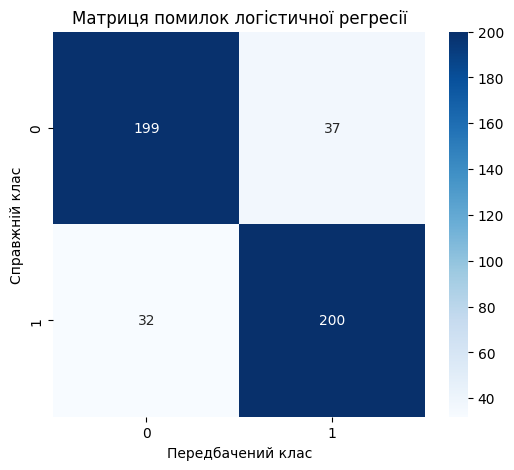

Матриця помилок (рядки — справжній клас, стовпці — прогноз):
[[199  37]
 [ 32 200]]


In [16]:
conf = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(conf, annot=True, fmt='d', cmap='Blues',
            xticklabels=[0, 1], yticklabels=[0, 1])
plt.title('Матриця помилок логістичної регресії')
plt.xlabel('Передбачений клас')
plt.ylabel('Справжній клас')
plt.show()
print("Матриця помилок (рядки — справжній клас, стовпці — прогноз):")
print(conf)

In [17]:
predictions_df = pd.DataFrame({
    'Справжній клас': y_test,
    'Передбачений клас': y_pred
}, index=y_test.index)
predictions_df['Результат'] = np.where(
    predictions_df['Справжній клас'] == predictions_df['Передбачений клас'],
    'Правильно', 'Помилка'
)
display(predictions_df.sample(min(10, len(predictions_df)), random_state=42))

,Справжній клас,Передбачений клас,Результат
1318,0,0,Правильно
244,0,0,Правильно
996,1,1,Правильно
930,0,0,Правильно
839,0,0,Правильно
1251,1,1,Правильно
335,1,1,Правильно
1670,0,0,Правильно
1118,0,0,Правильно
2175,1,1,Правильно


**Висновок щодо якості логістичної регресії:**  
_Яких помилок більше? Чи достатньо однієї метрики Accuracy?_

### 11. Підбір гіперпараметрів

Задайте набори параметрів для `LogisticRegression`. Проведіть підбір через **GridSearchCV** та **RandomizedSearchCV** із `cv=3`, `scoring='accuracy'`. Порівняйте найкращі параметри та отриману якість.

*Підказка:* дослідіть параметри `C`, `solver`, `max_iter`. Підбір виконуйте на **навчальній** вибірці.

In [18]:
param_grid = {
    'C': [0.01, 0.1, 1, 10],
    'solver': ['lbfgs', 'liblinear'],
    'max_iter': [500, 1000]
}
param_dist = {
    'C': [0.001, 0.01, 0.1, 1, 10, 100],
    'solver': ['lbfgs', 'liblinear'],
    'max_iter': [300, 500, 800, 1000, 1500]
}
print("Кількість комбінацій GridSearch:",
      len(param_grid['C']) * len(param_grid['solver']) * len(param_grid['max_iter']))

Кількість комбінацій GridSearch: 16


In [19]:
grid_search = GridSearchCV(
    LogisticRegression(random_state=42),
    param_grid,
    cv=3,
    scoring='accuracy',
    n_jobs=-1
)
grid_search.fit(X_train_scaled, y_train)
print("Найкращі параметри GridSearchCV:", grid_search.best_params_)
print(f"Найкраща середня CV Accuracy: {grid_search.best_score_:.4f}")

Найкращі параметри GridSearchCV: {'C': 10, 'max_iter': 500, 'solver': 'lbfgs'}
Найкраща середня CV Accuracy: 0.8749


In [20]:
random_search = RandomizedSearchCV(
    LogisticRegression(random_state=42),
    param_distributions=param_dist,
    n_iter=10,
    cv=3,
    scoring='accuracy',
    random_state=42,
    n_jobs=-1
)
random_search.fit(X_train_scaled, y_train)
print("Найкращі параметри RandomizedSearchCV:", random_search.best_params_)
print(f"Найкраща середня CV Accuracy: {random_search.best_score_:.4f}")

Найкращі параметри RandomizedSearchCV: {'solver': 'liblinear', 'max_iter': 800, 'C': 10}
Найкраща середня CV Accuracy: 0.8749


In [21]:
best_search = grid_search if grid_search.best_score_ >= random_search.best_score_ else random_search
best_tuned_model = best_search.best_estimator_
y_pred_tuned = best_tuned_model.predict(X_test_scaled)

tuned_accuracy = accuracy_score(y_test, y_pred_tuned)
print("Обраний метод:", "GridSearchCV" if best_search is grid_search else "RandomizedSearchCV")
print("Найкращі параметри:", best_search.best_params_)
print(f"Accuracy налаштованої моделі: {tuned_accuracy:.4f}")
print("\nClassification report:")
print(classification_report(y_test, y_pred_tuned, zero_division=0))
print(f"Зміна Accuracy відносно базової моделі: {tuned_accuracy - baseline_accuracy:+.4f}")

Обраний метод: GridSearchCV
Найкращі параметри: {'C': 10, 'max_iter': 500, 'solver': 'lbfgs'}
Accuracy налаштованої моделі: 0.8504

Classification report:
              precision    recall  f1-score   support

           0       0.86      0.84      0.85       236
           1       0.84      0.86      0.85       232

    accuracy                           0.85       468
   macro avg       0.85      0.85      0.85       468
weighted avg       0.85      0.85      0.85       468

Зміна Accuracy відносно базової моделі: -0.0021


**Висновок про підбір параметрів:**  
_Який метод пошуку обрав які параметри? Чи покращилась якість порівняно з базовою моделлю?_

### 12. Порівняння трьох моделей

Побудуйте також **метод опорних векторів (`SVC`)** і **дерево рішень (`DecisionTreeClassifier`)**. Порівняйте ці дві моделі з логістичною регресією за **Accuracy** та **F1-score** на однаковій тестовій вибірці. Оберіть найкращу модель і поясніть вибір.

In [22]:
models = {
    'Logistic Regression': model,
    'SVC': SVC(),
    'Decision Tree': DecisionTreeClassifier(random_state=42)
}

comparison_rows = []
model_predictions = {}

for name, clf in models.items():
    if name != 'Logistic Regression':
        clf.fit(X_train_scaled, y_train)
    pred = clf.predict(X_test_scaled)
    model_predictions[name] = pred
    comparison_rows.append({
        'Модель': name,
        'Accuracy': accuracy_score(y_test, pred),
        'F1-score': f1_score(y_test, pred, zero_division=0)
    })

comparison_df = pd.DataFrame(comparison_rows).set_index('Модель').sort_values(
    by=['F1-score', 'Accuracy'], ascending=False
)
display(comparison_df.style.format({'Accuracy': '{:.4f}', 'F1-score': '{:.4f}'}))

best_model_name = comparison_df.index[0]
print("Найкраща модель за F1-score (за рівності — за Accuracy):", best_model_name)
print("Показники найкращої моделі:")
display(comparison_df.loc[[best_model_name]])

,Accuracy,F1-score
Модель,,
SVC,0.9338,0.9328
Logistic Regression,0.8526,0.8529
Decision Tree,0.8248,0.8240


Найкраща модель за F1-score (за рівності — за Accuracy): SVC
Показники найкращої моделі:


,Accuracy,F1-score
Модель,,
SVC,0.933761,0.932755


### 13. Висновки до лабораторної роботи

Заповніть власними результатами (не залишайте відповіді з підказок):

1. Які особливості даних виявлено під час первинного аналізу?
2. Що показали дослідження викидів і кореляцій **на навчальній вибірці**?
3. Якої якості досягла базова логістична регресія?
4. Чи покращив підбір гіперпараметрів метрики моделі?
5. Яка з трьох моделей виявилася найкращою? Обґрунтуйте.

**Ваші висновки:**  
_Впишіть відповідь тут._

---
**Перед здачею:** перевірте, що всі потрібні клітинки виконуються послідовно, а результати й висновки присутні у файлі `.ipynb`.